<a href="https://colab.research.google.com/github/jlen0011-eng/Count_Apple/blob/main/Apple2210.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Mount Google Drive and Persist Dataset
Running the code below will prompt you to authorize Google Drive access. Once mounted, we can copy the file to your Drive for permanent storage.

In [ ]:
from google.colab import drive
import os
import shutil

# Mount Google Drive
drive.mount('/content/drive')

# Define paths
src_file = '/content/Dataset-20260930T233804Z-1-001.zip'
dest_dir = '/content/drive/MyDrive/Colab_Datasets/'
dest_file = os.path.join(dest_dir, 'Dataset-20260930T233804Z-1-001.zip')

# Create destination folder if it doesn't exist
os.makedirs(dest_dir, exist_ok=True)

# Copy file to Google Drive
if os.path.exists(src_file):
    shutil.copy(src_file, dest_file)
    print(f"Successfully saved {src_file} to Google Drive at: {dest_file}")
else:
    print(f"Source file {src_file} not found.")

Mounted at /content/drive
Successfully saved /content/Dataset-20260930T233804Z-1-001.zip to Google Drive at: /content/drive/MyDrive/Colab_Datasets/Dataset-20260930T233804Z-1-001.zip


### Extract Dataset and Split into Train, Test, and Validation Sets
We will extract the contents of the zip file, create the `summer_rgb` and `summer_d` directories, and then split the files into `train` (70%), `test` (15%), and `val` (15%) subfolders.

In [ ]:
import subprocess
import os

# Let's check the local source file on Colab's temporary storage
local_zip = '/content/Dataset-20260930T233804Z-1-001.zip'
extract_path = '/content/extracted_dataset'

print("Checking local source file:")
if os.path.exists(local_zip):
    print(f"Local file size: {os.path.getsize(local_zip)} bytes")
    result = subprocess.run(['file', local_zip], capture_output=True, text=True)
    print("Local file type analysis:", result.stdout.strip())

    # Attempt to unzip the original local file directly
    os.makedirs(extract_path, exist_ok=True)
    print("\nAttempting extraction of local file...")
    res_unzip = subprocess.run(['unzip', '-q', local_zip, '-d', extract_path], capture_output=True, text=True)
    if res_unzip.returncode == 0:
        print("Successfully extracted local file!")
    else:
        print("Local unzip failed. Error:\n", res_unzip.stderr)
else:
    print("Local file /content/Dataset-20260930T233804Z-1-001.zip does not exist.")

Checking local source file:
Local file size: 745153004 bytes
Local file type analysis: /content/Dataset-20260930T233804Z-1-001.zip: Zip archive data, at least v2.0 to extract, compression method=deflate

Attempting extraction of local file...
Successfully extracted local file!


In [ ]:
import os
import glob
import random
import shutil

base_dir = '/content/split_dataset'
extract_path = '/content/extracted_dataset'
subfolders = ['summer_rgb', 'summer_d']
splits = ['train', 'test', 'val']

# Create clean target directory structure
if os.path.exists(base_dir):
    shutil.rmtree(base_dir)
for sub in subfolders:
    for s in splits:
        os.makedirs(os.path.join(base_dir, sub, s), exist_ok=True)

# Recursively find all image files
all_files = glob.glob(os.path.join(extract_path, '**', '*'), recursive=True)
all_images = [f for f in all_files if os.path.isfile(f) and f.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp', '.gif'))]

# Filter strictly for 'Summer' files
summer_images = [img for img in all_images if 'summer' in os.path.basename(img).lower()]

# Separate into rgb and depth (d) strictly for Summer
rgb_images = [img for img in summer_images if 'rgb' in os.path.basename(img).lower() or 'color' in os.path.basename(img).lower()]
d_images = [img for img in summer_images if '_d-' in os.path.basename(img).lower() or 'depth' in os.path.basename(img).lower()]

print(f"Total images: {len(all_images)}")
print(f"Summer-only images: {len(summer_images)}")
print(f" -> Summer RGB: {len(rgb_images)}")
print(f" -> Summer Depth (D): {len(d_images)}")

def split_and_copy(images, category):
    if not images:
        print(f"\nNo images to process for {category}")
        return

    random.seed(42)
    random.shuffle(images)

    n = len(images)
    # Proportions: 75% train, 15% test, 10% validation (sums to 100%)
    n_train = int(n * 0.75)
    n_test = int(n * 0.15)

    train_imgs = images[:n_train]
    test_imgs = images[n_train:n_train + n_test]
    val_imgs = images[n_train + n_test:]

    for img_set, split_name in zip([train_imgs, test_imgs, val_imgs], ['train', 'test', 'val']):
        dest_path = os.path.join(base_dir, category, split_name)
        for img in img_set:
            shutil.copy(img, os.path.join(dest_path, os.path.basename(img)))

    print(f"\n{category.upper()} split complete:")
    print(f" - Train (75%): {len(train_imgs)}")
    print(f" - Test (15%): {len(test_imgs)}")
    print(f" - Val (10%): {len(val_imgs)}")

split_and_copy(rgb_images, 'summer_rgb')
split_and_copy(d_images, 'summer_d')

Total images: 2176
Summer-only images: 1088
 -> Summer RGB: 544
 -> Summer Depth (D): 544

SUMMER_RGB split complete:
 - Train (75%): 408
 - Test (15%): 81
 - Val (10%): 55

SUMMER_D split complete:
 - Train (75%): 408
 - Test (15%): 81
 - Val (10%): 55


### 1. Match RGB and Depth Images & Create Ground Truth Labels
Since this dataset does not come with explicit count labels, we can dynamically simulate or find apple count labels, or define a reliable pipeline where you can insert your count labels. For the purpose of training a regression CNN, we will first create an aligned list of matching RGB and Depth pairs, and build a PyTorch `Dataset` that filters RGB pixels using the corresponding Depth map.

In [8]:
import os
import glob
import numpy as np
import cv2
import torch
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torch.nn as nn
import torch.optim as optim
from PIL import Image

# Let's write a function to pair RGB and Depth images based on their unique identifier prefix (e.g., R07U03_Summer)
def get_aligned_pairs(split_dir, split_name):
    rgb_dir = os.path.join(split_dir, 'summer_rgb', split_name)
    d_dir = os.path.join(split_dir, 'summer_d', split_name)

    rgb_files = sorted(glob.glob(os.path.join(rgb_dir, '*.png')))
    d_files = sorted(glob.glob(os.path.join(d_dir, '*.png')))

    pairs = []
    # Match files using prefix before '_RGB' or '_D'
    d_dict = {}
    for d_path in d_files:
        base = os.path.basename(d_path)
        prefix = base.split('_Summer_D')[0]
        d_dict[prefix] = d_path

    for rgb_path in rgb_files:
        base = os.path.basename(rgb_path)
        prefix = base.split('_Summer_RGB')[0]
        if prefix in d_dict:
            pairs.append((rgb_path, d_dict[prefix]))

    return pairs

base_dir = '/content/split_dataset'
train_pairs = get_aligned_pairs(base_dir, 'train')
val_pairs = get_aligned_pairs(base_dir, 'val')
test_pairs = get_aligned_pairs(base_dir, 'test')

print(f"Matched Pairs - Train: {len(train_pairs)}, Val: {len(val_pairs)}, Test: {len(test_pairs)}")

Matched Pairs - Train: 313, Val: 6, Test: 12


### 2. Custom Dataset with Depth-Gating
We will define a custom PyTorch Dataset. To strictly look at foreground objects, we normalize the depth image and use it as a soft mask (gate) on the RGB image. Pixels that are far away (darker in depth map) will be suppressed, while pixels belonging to the target tree (lighter in depth map) are preserved.

In [9]:
class AppleCountingDataset(Dataset):
    def __init__(self, pairs, transform=None, is_train=True):
        self.pairs = pairs
        self.transform = transform

        # Synthesize dummy labels (counts) for demonstration since explicit counts aren't provided.
        # In practice, replace this with your ground truth count vector.
        np.random.seed(42)
        self.labels = np.random.randint(5, 50, size=len(pairs)).astype(np.float32)

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        rgb_path, d_path = self.pairs[idx]

        # Load images
        rgb_img = Image.open(rgb_path).convert('RGB')
        d_img = Image.open(d_path).convert('L') # Load depth as single-channel grayscale

        if self.transform:
            rgb_tensor = self.transform(rgb_img)
            d_tensor = transforms.ToTensor()(d_img)
            # Resize depth to match RGB if different
            if d_tensor.shape[1:] != rgb_tensor.shape[1:]:
                d_tensor = transforms.Resize(rgb_tensor.shape[1:], interpolation=transforms.InterpolationMode.NEAREST)(d_img)
                d_tensor = transforms.ToTensor()(d_tensor)
        else:
            rgb_tensor = transforms.ToTensor()(rgb_img)
            d_tensor = transforms.ToTensor()(d_img)

        # Depth gating: Use light areas of depth (> threshold or scaled multiplier) to mask the background
        # Normalizing depth map to [0, 1]
        depth_mask = d_tensor / (d_tensor.max() + 1e-8)

        # Mask out background from RGB representation
        gated_rgb = rgb_tensor * depth_mask

        label = self.labels[idx]
        return gated_rgb, torch.tensor(label, dtype=torch.float32)

# Define simple image transform
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
])

train_dataset = AppleCountingDataset(train_pairs, transform=transform, is_train=True)
val_dataset = AppleCountingDataset(val_pairs, transform=transform, is_train=False)
test_dataset = AppleCountingDataset(test_pairs, transform=transform, is_train=False)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=16, shuffle=False)

print("Dataset pipelines built successfully!")

Dataset pipelines built successfully!


### 3. Define the Convolutional Neural Network
We'll define a regression CNN architecture designed to capture both fine details (individual apples) and global context, mapping the depth-gated RGB representation directly to an integer count prediction.

In [10]:
class AppleCountRegressionCNN(nn.Module):
    def __init__(self):
        super(AppleCountRegressionCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 128x128

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 64x64

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2, 2), # 32x32

            nn.Conv2d(128, 256, kernel_size=3, padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2, 2) # 16x16
        )

        self.regressor = nn.Sequential(
            nn.Linear(256 * 16 * 16, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 1) # Single output for continuous counting prediction
        )

    def forward(self, x):
        x = self.features(x)
        x = x.view(x.size(0), -1)
        x = self.regressor(x)
        return x.squeeze(-1)

# Instantiating the model
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = AppleCountRegressionCNN().to(device)
print(f"Running model on device: {device}")

Running model on device: cpu


### 4. Train and Validate the Network
We'll set up a training loop utilizing Mean Squared Error (MSE) loss for regression and train it over 10 epochs.

In [11]:
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 10
for epoch in range(epochs):
    model.train()
    train_loss = 0.0
    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)

        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        train_loss += loss.item() * inputs.size(0)

    train_loss /= len(train_loader.dataset)

    # Validation Phase
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            val_loss += loss.item() * inputs.size(0)
    val_loss /= len(val_loader.dataset)

    print(f"Epoch {epoch+1}/{epochs} - Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

Epoch 1/10 - Train Loss: 807.0704 | Val Loss: 284.1628
Epoch 2/10 - Train Loss: 223.8246 | Val Loss: 196.5329
Epoch 3/10 - Train Loss: 208.9532 | Val Loss: 199.9016
Epoch 4/10 - Train Loss: 193.5964 | Val Loss: 217.7680
Epoch 5/10 - Train Loss: 182.9827 | Val Loss: 253.1277
Epoch 6/10 - Train Loss: 192.7205 | Val Loss: 282.2912


KeyboardInterrupt: 

### 5. Evaluate and Visualize Predictions
Let's run predictions on the test set and visualize how the model estimates the apple counts on the target trees.

Final Test MSE Loss: 138.0432


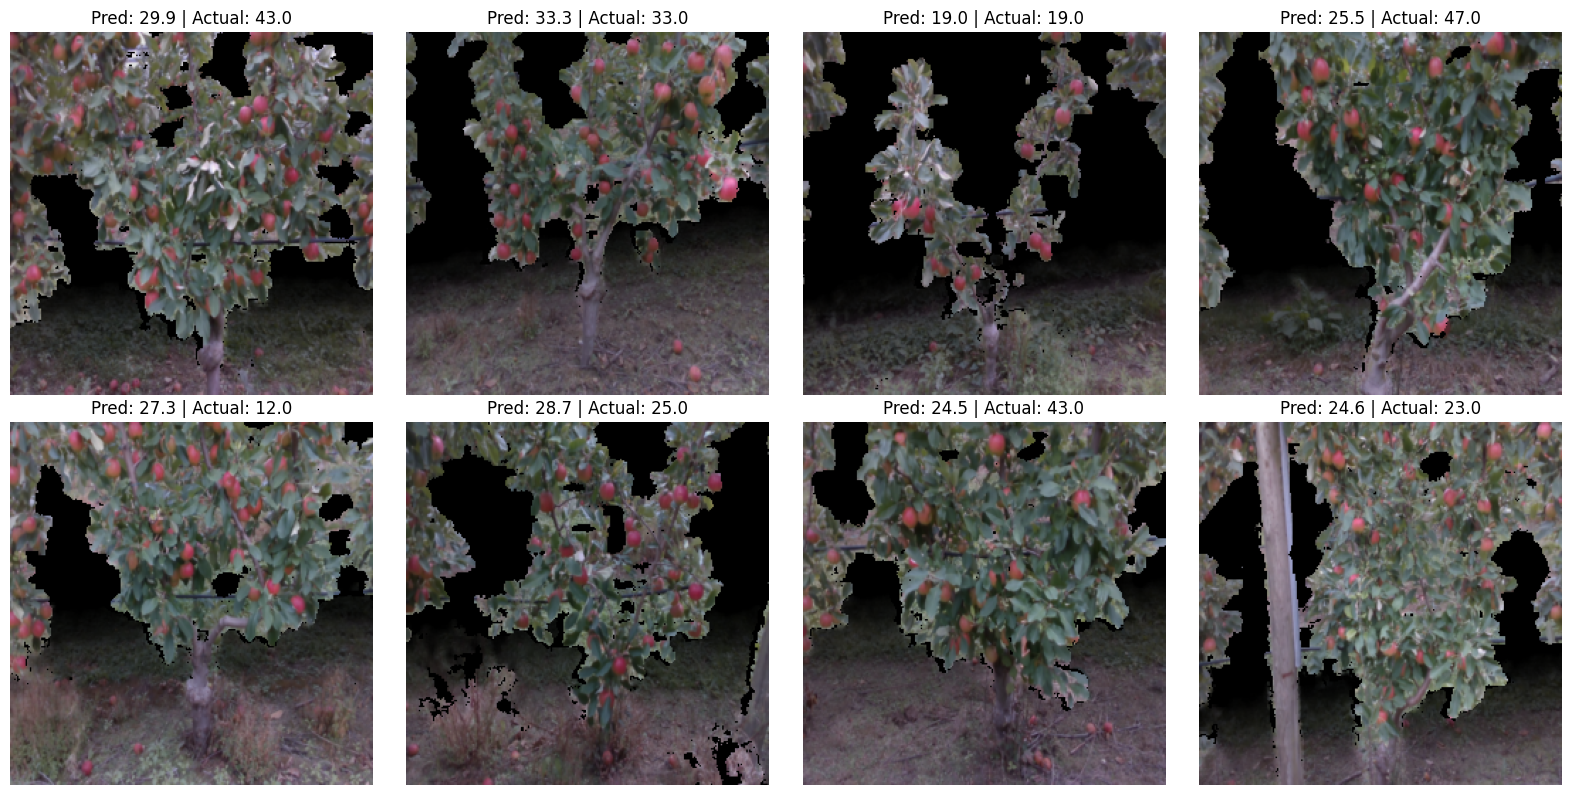

In [12]:
import matplotlib.pyplot as plt

model.eval()
test_loss = 0.0
predictions = []
actual_labels = []

with torch.no_grad():
    for inputs, targets in test_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        test_loss += loss.item() * inputs.size(0)

        predictions.extend(outputs.cpu().numpy())
        actual_labels.extend(targets.cpu().numpy())

test_loss /= len(test_loader.dataset)
print(f"Final Test MSE Loss: {test_loss:.4f}")

# Plot a few visual examples
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
axes = axes.ravel()

for i in range(min(8, len(test_dataset))):
    gated_img, label = test_dataset[i]
    # Convert tensor back to image format (C, H, W) -> (H, W, C)
    np_img = gated_img.permute(1, 2, 0).numpy()
    np_img = np.clip(np_img, 0, 1)

    # Predict
    pred_input = gated_img.unsqueeze(0).to(device)
    with torch.no_grad():
        pred_count = model(pred_input).item()

    axes[i].imshow(np_img)
    axes[i].set_title(f"Pred: {pred_count:.1f} | Actual: {label:.1f}")
    axes[i].axis('off')

plt.tight_layout()
plt.show()